# Part 1: Audit Dataset, Seleksi Fitur, dan Pemeriksaan Distribusi Aliran Trafik
Tujuan: Memverifikasi direktori kerja, membersihkan identifier statis (socket attributes), dan memvalidasi ketersediaan fitur numerik.

In [ ]:
import pandas as pd
from pathlib import Path
from collections import Counter
import shutil

# ============================================================
# KONFIGURASI PART 1
# ============================================================
RAW_CSV = Path(r"I:\skripsi\NIDS\dataset\raw\NF-UQ-NIDS-v2.csv")

LABEL_COLUMN = "Label"
ATTACK_COLUMN = "Attack"
BENIGN_LABEL = "0"

CHUNKSIZE = 50_000 # Menentukan ukuran chunk untuk membaca CSV secara bertahap

OUTPUT_DIR = Path("prepared_data")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ============================================================
# Cek free disk
# ============================================================
total, used, free = shutil.disk_usage(Path.cwd())

print("Lokasi kerja:", Path.cwd())
print(f"Free disk: {free / (1024**3):.2f} GB")
print(f"Output akan disimpan ke: {OUTPUT_DIR.resolve()}")

Lokasi kerja: i:\skripsi\NIDS\notebooks
Free disk: 356.84 GB
Output akan disimpan ke: I:\skripsi\NIDS\notebooks\prepared_data


In [2]:
# Baca header saja, sangat ringan
columns = pd.read_csv(RAW_CSV, nrows=0).columns.tolist()

print("Jumlah kolom:", len(columns))
print("\nDaftar kolom:")
for i, col in enumerate(columns):
    print(i, col)

Jumlah kolom: 46

Daftar kolom:
0 IPV4_SRC_ADDR
1 L4_SRC_PORT
2 IPV4_DST_ADDR
3 L4_DST_PORT
4 PROTOCOL
5 L7_PROTO
6 IN_BYTES
7 IN_PKTS
8 OUT_BYTES
9 OUT_PKTS
10 TCP_FLAGS
11 CLIENT_TCP_FLAGS
12 SERVER_TCP_FLAGS
13 FLOW_DURATION_MILLISECONDS
14 DURATION_IN
15 DURATION_OUT
16 MIN_TTL
17 MAX_TTL
18 LONGEST_FLOW_PKT
19 SHORTEST_FLOW_PKT
20 MIN_IP_PKT_LEN
21 MAX_IP_PKT_LEN
22 SRC_TO_DST_SECOND_BYTES
23 DST_TO_SRC_SECOND_BYTES
24 RETRANSMITTED_IN_BYTES
25 RETRANSMITTED_IN_PKTS
26 RETRANSMITTED_OUT_BYTES
27 RETRANSMITTED_OUT_PKTS
28 SRC_TO_DST_AVG_THROUGHPUT
29 DST_TO_SRC_AVG_THROUGHPUT
30 NUM_PKTS_UP_TO_128_BYTES
31 NUM_PKTS_128_TO_256_BYTES
32 NUM_PKTS_256_TO_512_BYTES
33 NUM_PKTS_512_TO_1024_BYTES
34 NUM_PKTS_1024_TO_1514_BYTES
35 TCP_WIN_MAX_IN
36 TCP_WIN_MAX_OUT
37 ICMP_TYPE
38 ICMP_IPV4_TYPE
39 DNS_QUERY_ID
40 DNS_QUERY_TYPE
41 DNS_TTL_ANSWER
42 FTP_COMMAND_RET_CODE
43 Label
44 Attack
45 Dataset


In [3]:
if LABEL_COLUMN not in columns:
    print(f"WARNING: kolom label '{LABEL_COLUMN}' tidak ditemukan.")
    print("Silakan cek daftar kolom di atas dan ubah LABEL_COLUMN.")
else:
    print(f"Kolom label '{LABEL_COLUMN}' ditemukan.")

if ATTACK_COLUMN not in columns:
    print(f"WARNING: kolom attack '{ATTACK_COLUMN}' tidak ditemukan.")
    print("Silakan cek daftar kolom di atas dan ubah ATTACK_COLUMN.")
else:
    print(f"Kolom attack '{ATTACK_COLUMN}' ditemukan.")

Kolom label 'Label' ditemukan.
Kolom attack 'Attack' ditemukan.


In [4]:
DROP_COLUMNS = [
    "IPV4_SRC_ADDR",
    "IPV4_DST_ADDR",
    "L4_SRC_PORT",
    "L4_DST_PORT",
]

protected_columns = {LABEL_COLUMN, ATTACK_COLUMN}

drop_columns_existing = [
    col
    for col in DROP_COLUMNS
    if col in columns and col not in protected_columns
]

candidate_feature_columns = [
    col
    for col in columns
    if col not in protected_columns and col not in drop_columns_existing
]

print("Kolom yang akan dibuang:")
print(drop_columns_existing)

print("\nJumlah feature candidate:")
print(len(candidate_feature_columns))

print("\nFeature candidate:")
print(candidate_feature_columns)

Kolom yang akan dibuang:
['IPV4_SRC_ADDR', 'IPV4_DST_ADDR', 'L4_SRC_PORT', 'L4_DST_PORT']

Jumlah feature candidate:
40

Feature candidate:
['PROTOCOL', 'L7_PROTO', 'IN_BYTES', 'IN_PKTS', 'OUT_BYTES', 'OUT_PKTS', 'TCP_FLAGS', 'CLIENT_TCP_FLAGS', 'SERVER_TCP_FLAGS', 'FLOW_DURATION_MILLISECONDS', 'DURATION_IN', 'DURATION_OUT', 'MIN_TTL', 'MAX_TTL', 'LONGEST_FLOW_PKT', 'SHORTEST_FLOW_PKT', 'MIN_IP_PKT_LEN', 'MAX_IP_PKT_LEN', 'SRC_TO_DST_SECOND_BYTES', 'DST_TO_SRC_SECOND_BYTES', 'RETRANSMITTED_IN_BYTES', 'RETRANSMITTED_IN_PKTS', 'RETRANSMITTED_OUT_BYTES', 'RETRANSMITTED_OUT_PKTS', 'SRC_TO_DST_AVG_THROUGHPUT', 'DST_TO_SRC_AVG_THROUGHPUT', 'NUM_PKTS_UP_TO_128_BYTES', 'NUM_PKTS_128_TO_256_BYTES', 'NUM_PKTS_256_TO_512_BYTES', 'NUM_PKTS_512_TO_1024_BYTES', 'NUM_PKTS_1024_TO_1514_BYTES', 'TCP_WIN_MAX_IN', 'TCP_WIN_MAX_OUT', 'ICMP_TYPE', 'ICMP_IPV4_TYPE', 'DNS_QUERY_ID', 'DNS_QUERY_TYPE', 'DNS_TTL_ANSWER', 'FTP_COMMAND_RET_CODE', 'Dataset']


In [5]:
sample_columns = candidate_feature_columns + [LABEL_COLUMN, ATTACK_COLUMN]

sample = pd.read_csv(
    RAW_CSV,
    nrows=1000,
    usecols=sample_columns
)

print("Shape sample:", sample.shape)

sample.head()

Shape sample: (1000, 42)


,PROTOCOL,L7_PROTO,IN_BYTES,IN_PKTS,OUT_BYTES,OUT_PKTS,TCP_FLAGS,CLIENT_TCP_FLAGS,SERVER_TCP_FLAGS,FLOW_DURATION_MILLISECONDS,...,TCP_WIN_MAX_OUT,ICMP_TYPE,ICMP_IPV4_TYPE,DNS_QUERY_ID,DNS_QUERY_TYPE,DNS_TTL_ANSWER,FTP_COMMAND_RET_CODE,Label,Attack,Dataset
0,6,7.0,420,3,0,0,2,2,0,4293092,...,0,35840,140,0,0,0,0.0,1,DoS,NF-BoT-IoT-v2
1,6,7.0,280,2,40,1,22,2,20,4294499,...,0,0,0,0,0,0,0.0,1,DoS,NF-BoT-IoT-v2
2,6,0.0,44,1,40,1,22,2,20,0,...,0,0,0,0,0,0,0.0,0,Benign,NF-ToN-IoT-v2
3,6,0.0,44,1,40,1,22,2,20,0,...,0,0,0,0,0,0,0.0,0,Benign,NF-ToN-IoT-v2
4,6,0.0,44,1,40,1,22,2,20,0,...,0,0,0,0,0,0,0.0,0,Benign,NF-ToN-IoT-v2


In [7]:
sample_large = pd.read_csv(
    RAW_CSV,
    nrows=1_000_000,
    usecols=[LABEL_COLUMN, ATTACK_COLUMN]
)

print("Shape sample 1 juta baris:", sample_large.shape)

print("\nLabel distribution:")
print(sample_large[LABEL_COLUMN].value_counts())

print("\nAttack distribution:")
print(sample_large[ATTACK_COLUMN].value_counts().head(50))

Shape sample 1 juta baris: (1000000, 2)

Label distribution:
Label
1    668941
0    331059
Name: count, dtype: int64

Attack distribution:
Attack
Benign            331059
DDoS              285935
DoS               235662
scanning           50360
Reconnaissance     34187
xss                32341
password           14996
injection           9006
Bot                 1884
Brute Force         1614
Infilteration       1568
Exploits             410
Fuzzers              294
Backdoor             241
Generic              220
mitm                  99
ransomware            43
Analysis              36
Theft                 23
Shellcode             18
Worms                  4
Name: count, dtype: int64


In [8]:
RUN_FULL_LABEL_ATTACK_SCAN = True

if RUN_FULL_LABEL_ATTACK_SCAN:
    label_counts = Counter()
    attack_counts = Counter()

    total_rows = 0

    usecols = [LABEL_COLUMN, ATTACK_COLUMN]

    for chunk_index, chunk in enumerate(
        pd.read_csv(
            RAW_CSV,
            usecols=usecols,
            chunksize=CHUNKSIZE,
            low_memory=False
        )
    ):
        total_rows += len(chunk)

        label_counts.update(
            chunk[LABEL_COLUMN]
            .fillna("MISSING")
            .astype(str)
            .value_counts()
            .to_dict()
        )

        attack_counts.update(
            chunk[ATTACK_COLUMN]
            .fillna("MISSING")
            .astype(str)
            .value_counts()
            .to_dict()
        )

        if chunk_index % 50 == 0:
            print(f"Chunk {chunk_index} | total rows: {total_rows}")

    print("\nScan selesai.")
    print("Total rows:", total_rows)

    print("\nLabel counts:")
    for label, count in label_counts.most_common():
        print(label, count)

    print("\nAttack counts top 50:")
    for attack, count in attack_counts.most_common(50):
        print(attack, count)

Chunk 0 | total rows: 50000
Chunk 50 | total rows: 2550000
Chunk 100 | total rows: 5050000
Chunk 150 | total rows: 7550000
Chunk 200 | total rows: 10050000
Chunk 250 | total rows: 12550000
Chunk 300 | total rows: 15050000
Chunk 350 | total rows: 17550000
Chunk 400 | total rows: 20050000
Chunk 450 | total rows: 22550000
Chunk 500 | total rows: 25050000
Chunk 550 | total rows: 27550000
Chunk 600 | total rows: 30050000
Chunk 650 | total rows: 32550000
Chunk 700 | total rows: 35050000
Chunk 750 | total rows: 37550000
Chunk 800 | total rows: 40050000
Chunk 850 | total rows: 42550000
Chunk 900 | total rows: 45050000
Chunk 950 | total rows: 47550000
Chunk 1000 | total rows: 50050000
Chunk 1050 | total rows: 52550000
Chunk 1100 | total rows: 55050000
Chunk 1150 | total rows: 57550000
Chunk 1200 | total rows: 60050000
Chunk 1250 | total rows: 62550000
Chunk 1300 | total rows: 65050000
Chunk 1350 | total rows: 67550000
Chunk 1400 | total rows: 70050000
Chunk 1450 | total rows: 72550000
Chunk 150

# Part 2
## Pembagian data streaming

In [ ]:
import json
import shutil
import numpy as np
import pandas as pd
from pathlib import Path

# ============================================================
# KONFIGURASI PART 2
# ============================================================

RAW_CSV = r"I:\skripsi\NIDS\dataset\raw\NF-UQ-NIDS-v2.csv"

CSV_SEP = ","

LABEL_COLUMN = "Label"
ATTACK_COLUMN = "Attack"
BENIGN_LABEL = 0

# Kolom identifier yang tidak boleh dipakai sebagai feature.
DROP_COLUMNS = [
    "IPV4_SRC_ADDR",
    "IPV4_DST_ADDR",
    "L4_SRC_PORT",
    "L4_DST_PORT",
]

# ============================================================
# ZERO-DAY ATTACK YANG INGIN DIGUNAKAN
# ============================================================
# Isi sesuai hasil Part 1.
# Contoh: ["DDoS"]
#
# Jika ingin memakai SEMUA attack sebagai zero-day, set:
# USE_ALL_ATTACKS = True
#
# Atau bisa juga:
# SELECTED_UNSEEN_ATTACKS = ["__ALL__"]
# ============================================================
SELECTED_UNSEEN_ATTACKS = ["DDoS"]
USE_ALL_ATTACKS = False

# ============================================================
# SPLIT DATA BENIGN
# ============================================================
# 80% train, 20% test.
# Ini split aproximasi per chunk, bukan exact global random split,
# tetapi cukup aman dan hemat RAM.
TRAIN_RATIO = 0.80

# ============================================================
# PROSES CHUNKING
# ============================================================
# Jika RAM masih berat, turunkan menjadi 20000 atau 10000.
CHUNKSIZE = 50_000

# Untuk testing awal, batasi beberapa chunk saja.
# Jika sudah yakin, ubah menjadi:
# LIMIT_CHUNKS = None
LIMIT_CHUNKS = 5

# Jika True, folder output akan dihapus sebelum proses.
# Aktifkan saat testing / mengulang dari awal.
CLEAR_OUTPUT_DIRS = True

# ============================================================
# OUTPUT
# ============================================================
OUTPUT_DIR = Path("prepared_data")

TRAIN_DIR = OUTPUT_DIR / "benign_train_parts"
TEST_BENIGN_DIR = OUTPUT_DIR / "benign_test_parts"
UNSEEN_ATTACK_DIR = OUTPUT_DIR / "unseen_attack_test_parts"

# ============================================================
# SEED & FEATURE FILTERING
# ============================================================
SEED = 42

# Saat mengecek sample kolom, hanya ambil feature yang minimal
# 95% nilainya bisa dikonversi menjadi numeric.
FEATURE_VALID_RATIO_THRESHOLD = 0.95
SAMPLE_ROWS_FOR_FEATURE_CHECK = 5000

print("Konfigurasi Part 2 siap.")
print("RAW_CSV:", RAW_CSV)
print("OUTPUT_DIR:", OUTPUT_DIR.resolve())

Konfigurasi Part 2 siap.
RAW_CSV: I:\skripsi\NIDS\dataset\raw\NF-UQ-NIDS-v2.csv
OUTPUT_DIR: I:\skripsi\NIDS\notebooks\prepared_data


In [21]:
directories = [
    TRAIN_DIR,
    TEST_BENIGN_DIR,
    UNSEEN_ATTACK_DIR,
]

if CLEAR_OUTPUT_DIRS:
    for directory in directories:
        if directory.exists():
            shutil.rmtree(directory)
            print(f"Menghapus folder lama: {directory}")

for directory in directories:
    directory.mkdir(parents=True, exist_ok=True)
    print(f"Folder siap: {directory}")

Menghapus folder lama: prepared_data\benign_train_parts
Menghapus folder lama: prepared_data\benign_test_parts
Menghapus folder lama: prepared_data\unseen_attack_test_parts
Folder siap: prepared_data\benign_train_parts
Folder siap: prepared_data\benign_test_parts
Folder siap: prepared_data\unseen_attack_test_parts


In [22]:
# Baca header saja
columns = pd.read_csv(
    RAW_CSV,
    nrows=0,
    sep=CSV_SEP
).columns.tolist()

print("Jumlah kolom:", len(columns))

protected_columns = {LABEL_COLUMN, ATTACK_COLUMN}

drop_columns_existing = [
    col
    for col in DROP_COLUMNS
    if col in columns and col not in protected_columns
]

candidate_feature_columns = [
    col
    for col in columns
    if col not in protected_columns and col not in drop_columns_existing
]

print("\nKolom yang dibuang:")
print(drop_columns_existing)

print("\nJumlah kandidat feature:")
print(len(candidate_feature_columns))

Jumlah kolom: 46

Kolom yang dibuang:
['IPV4_SRC_ADDR', 'IPV4_DST_ADDR', 'L4_SRC_PORT', 'L4_DST_PORT']

Jumlah kandidat feature:
40


In [23]:
sample_columns = candidate_feature_columns + [LABEL_COLUMN]

if ATTACK_COLUMN in columns:
    sample_columns = sample_columns + [ATTACK_COLUMN]

sample = pd.read_csv(
    RAW_CSV,
    nrows=SAMPLE_ROWS_FOR_FEATURE_CHECK,
    usecols=sample_columns,
    sep=CSV_SEP,
    low_memory=False
)

print("Shape sample:", sample.shape)

sample_features = sample[candidate_feature_columns].apply(
    lambda col: pd.to_numeric(col, errors="coerce")
)

sample_features.replace([np.inf, -np.inf], np.nan, inplace=True)

valid_ratio = sample_features.notna().mean()

feature_columns = valid_ratio[
    valid_ratio >= FEATURE_VALID_RATIO_THRESHOLD
].index.tolist()

excluded_feature_columns = valid_ratio[
    valid_ratio < FEATURE_VALID_RATIO_THRESHOLD
].index.tolist()

print("\nFeature numeric yang dipakai:")
print("Jumlah:", len(feature_columns))
print(feature_columns)

print("\nFeature yang tidak dipakai karena terlalu banyak non-numeric:")
print("Jumlah:", len(excluded_feature_columns))
print(excluded_feature_columns)

if len(feature_columns) == 0:
    raise ValueError("Tidak ada feature numeric yang bisa dipakai. Periksa dataset Anda.")

Shape sample: (5000, 42)

Feature numeric yang dipakai:
Jumlah: 39
['PROTOCOL', 'L7_PROTO', 'IN_BYTES', 'IN_PKTS', 'OUT_BYTES', 'OUT_PKTS', 'TCP_FLAGS', 'CLIENT_TCP_FLAGS', 'SERVER_TCP_FLAGS', 'FLOW_DURATION_MILLISECONDS', 'DURATION_IN', 'DURATION_OUT', 'MIN_TTL', 'MAX_TTL', 'LONGEST_FLOW_PKT', 'SHORTEST_FLOW_PKT', 'MIN_IP_PKT_LEN', 'MAX_IP_PKT_LEN', 'SRC_TO_DST_SECOND_BYTES', 'DST_TO_SRC_SECOND_BYTES', 'RETRANSMITTED_IN_BYTES', 'RETRANSMITTED_IN_PKTS', 'RETRANSMITTED_OUT_BYTES', 'RETRANSMITTED_OUT_PKTS', 'SRC_TO_DST_AVG_THROUGHPUT', 'DST_TO_SRC_AVG_THROUGHPUT', 'NUM_PKTS_UP_TO_128_BYTES', 'NUM_PKTS_128_TO_256_BYTES', 'NUM_PKTS_256_TO_512_BYTES', 'NUM_PKTS_512_TO_1024_BYTES', 'NUM_PKTS_1024_TO_1514_BYTES', 'TCP_WIN_MAX_IN', 'TCP_WIN_MAX_OUT', 'ICMP_TYPE', 'ICMP_IPV4_TYPE', 'DNS_QUERY_ID', 'DNS_QUERY_TYPE', 'DNS_TTL_ANSWER', 'FTP_COMMAND_RET_CODE']

Feature yang tidak dipakai karena terlalu banyak non-numeric:
Jumlah: 1
['Dataset']


In [24]:
def normalize_label_series(series):
    """
    Mengubah label menjadi:
    0 = benign / normal
    1 = attack / anomaly
    """
    if pd.api.types.is_numeric_dtype(series):
        return (series != BENIGN_LABEL).astype("int8")

    s = series.astype(str).str.strip().str.lower()

    benign_exact = {"benign", "normal", "0", "false", "no"}

    is_benign = (
        s.isin(benign_exact)
        | s.str.contains("benign", regex=False)
        | s.str.contains("normal", regex=False)
    )

    return np.where(is_benign, 0, 1).astype("int8")


def normalize_attack_column(chunk):
    """
    Memastikan kolom attack category tersedia.
    """
    chunk = chunk.copy()

    if ATTACK_COLUMN not in chunk.columns:
        chunk[ATTACK_COLUMN] = np.where(
            chunk[LABEL_COLUMN] == 0,
            "Benign",
            "Attack"
        )
    else:
        chunk[ATTACK_COLUMN] = (
            chunk[ATTACK_COLUMN]
            .fillna("Unknown")
            .astype(str)
        )

        benign_mask = chunk[LABEL_COLUMN] == 0

        unknown_mask = (
            chunk[ATTACK_COLUMN]
            .str.strip()
            .str.lower()
            .isin({"", "nan", "unknown"})
        )

        chunk.loc[benign_mask & unknown_mask, ATTACK_COLUMN] = "Benign"

    return chunk


def clean_chunk_features(chunk, feature_columns):
    """
    Bersihkan feature dalam satu chunk:
    - konversi ke numeric
    - buang +/- infinity
    - buang baris dengan NaN pada feature
    - simpan sebagai float32
    """
    if not feature_columns:
        return None

    features = chunk[feature_columns].apply(
        lambda col: pd.to_numeric(col, errors="coerce")
    )

    features.replace([np.inf, -np.inf], np.nan, inplace=True)

    valid_index = features.dropna().index

    if len(valid_index) == 0:
        return None

    cleaned = chunk.loc[valid_index].copy()
    cleaned[feature_columns] = features.loc[valid_index].astype("float32")

    return cleaned


def save_part(df, directory, chunk_idx):
    """
    Simpan satu DataFrame chunk sebagai file Parquet.
    """
    if df is None or df.empty:
        return 0

    file_path = directory / f"part_{chunk_idx:06d}.parquet"

    df.to_parquet(
        file_path,
        index=False,
        compression="snappy"
    )

    return len(df)


def count_parquet_files(directory):
    return len(list(directory.glob("*.parquet")))

In [25]:
rng = np.random.default_rng(SEED)

use_all_attacks = (
    USE_ALL_ATTACKS
    or (
        len(SELECTED_UNSEEN_ATTACKS) == 1
        and str(SELECTED_UNSEEN_ATTACKS[0]).strip().lower() == "__all__"
    )
)

if use_all_attacks:
    selected_lower = None
    print("Mode attack: SEMUA attack akan disimpan sebagai unseen attack.")
else:
    selected_lower = {
        str(cat).strip().lower()
        for cat in SELECTED_UNSEEN_ATTACKS
    }
    print("Mode attack: hanya kategori berikut yang disimpan sebagai unseen attack:")
    print(selected_lower)

usecols = feature_columns + [LABEL_COLUMN]

if ATTACK_COLUMN in columns:
    usecols = usecols + [ATTACK_COLUMN]

print("\nKolom yang dibaca dari CSV:")
print(usecols)

counters = {
    "chunks_processed": 0,
    "rows_read": 0,
    "rows_after_clean": 0,
    "dropped_invalid_or_missing": 0,
    "benign_train": 0,
    "benign_test": 0,
    "unseen_attack_test": 0,
    "attack_ignored": 0,
}

found_unseen_categories = set()

reader = pd.read_csv(
    RAW_CSV,
    usecols=usecols,
    chunksize=CHUNKSIZE,
    sep=CSV_SEP,
    low_memory=False
)

for chunk_idx, chunk in enumerate(reader):

    if LIMIT_CHUNKS is not None and chunk_idx >= LIMIT_CHUNKS:
        print(f"\nMencapai LIMIT_CHUNKS = {LIMIT_CHUNKS}. Proses dihentikan.")
        break

    rows_read = len(chunk)
    counters["rows_read"] += rows_read

    # Buang baris tanpa label
    if LABEL_COLUMN not in chunk.columns:
        raise KeyError(f"Kolom label '{LABEL_COLUMN}' tidak ditemukan dalam chunk.")

    before_drop_label = len(chunk)
    chunk = chunk.dropna(subset=[LABEL_COLUMN])
    counters["dropped_invalid_or_missing"] += before_drop_label - len(chunk)

    if chunk.empty:
        continue

    # Normalisasi label dan attack
    chunk[LABEL_COLUMN] = normalize_label_series(chunk[LABEL_COLUMN])
    chunk = normalize_attack_column(chunk)

    # Bersihkan feature
    cleaned = clean_chunk_features(chunk, feature_columns)

    if cleaned is None or cleaned.empty:
        counters["dropped_invalid_or_missing"] += len(chunk)
        continue

    counters["rows_after_clean"] += len(cleaned)
    counters["dropped_invalid_or_missing"] += len(chunk) - len(cleaned)

    # ==============================================================
    # 1. Proses benign
    # ==============================================================
    benign_chunk = cleaned[cleaned[LABEL_COLUMN] == 0]

    if not benign_chunk.empty:
        random_values = rng.random(len(benign_chunk))

        train_part = benign_chunk[random_values < TRAIN_RATIO]
        test_part = benign_chunk[random_values >= TRAIN_RATIO]

        counters["benign_train"] += save_part(
            train_part,
            TRAIN_DIR,
            chunk_idx
        )

        counters["benign_test"] += save_part(
            test_part,
            TEST_BENIGN_DIR,
            chunk_idx
        )

    # ==============================================================
    # 2. Proses attack zero-day
    # ==============================================================
    attack_chunk = cleaned[cleaned[LABEL_COLUMN] != 0]

    if not attack_chunk.empty:

        if use_all_attacks:
            unseen_part = attack_chunk
        else:
            attack_category_lower = (
                attack_chunk[ATTACK_COLUMN]
                .astype(str)
                .str.strip()
                .str.lower()
            )

            unseen_mask = attack_category_lower.isin(selected_lower)
            unseen_part = attack_chunk[unseen_mask]

            counters["attack_ignored"] += len(attack_chunk) - len(unseen_part)

        counters["unseen_attack_test"] += save_part(
            unseen_part,
            UNSEEN_ATTACK_DIR,
            chunk_idx
        )

        if not unseen_part.empty:
            found_unseen_categories.update(
                unseen_part[ATTACK_COLUMN]
                .astype(str)
                .str.strip()
                .str.lower()
                .unique()
            )

    counters["chunks_processed"] += 1

    if chunk_idx % 10 == 0:
        print(
            f"Chunk {chunk_idx} | "
            f"rows_read={counters['rows_read']} | "
            f"benign_train={counters['benign_train']} | "
            f"benign_test={counters['benign_test']} | "
            f"unseen_attack={counters['unseen_attack_test']}"
        )

print("\nProses pembagian data selesai.")
print(json.dumps(counters, indent=4))

Mode attack: hanya kategori berikut yang disimpan sebagai unseen attack:
{'ddos'}

Kolom yang dibaca dari CSV:
['PROTOCOL', 'L7_PROTO', 'IN_BYTES', 'IN_PKTS', 'OUT_BYTES', 'OUT_PKTS', 'TCP_FLAGS', 'CLIENT_TCP_FLAGS', 'SERVER_TCP_FLAGS', 'FLOW_DURATION_MILLISECONDS', 'DURATION_IN', 'DURATION_OUT', 'MIN_TTL', 'MAX_TTL', 'LONGEST_FLOW_PKT', 'SHORTEST_FLOW_PKT', 'MIN_IP_PKT_LEN', 'MAX_IP_PKT_LEN', 'SRC_TO_DST_SECOND_BYTES', 'DST_TO_SRC_SECOND_BYTES', 'RETRANSMITTED_IN_BYTES', 'RETRANSMITTED_IN_PKTS', 'RETRANSMITTED_OUT_BYTES', 'RETRANSMITTED_OUT_PKTS', 'SRC_TO_DST_AVG_THROUGHPUT', 'DST_TO_SRC_AVG_THROUGHPUT', 'NUM_PKTS_UP_TO_128_BYTES', 'NUM_PKTS_128_TO_256_BYTES', 'NUM_PKTS_256_TO_512_BYTES', 'NUM_PKTS_512_TO_1024_BYTES', 'NUM_PKTS_1024_TO_1514_BYTES', 'TCP_WIN_MAX_IN', 'TCP_WIN_MAX_OUT', 'ICMP_TYPE', 'ICMP_IPV4_TYPE', 'DNS_QUERY_ID', 'DNS_QUERY_TYPE', 'DNS_TTL_ANSWER', 'FTP_COMMAND_RET_CODE', 'Label', 'Attack']
Chunk 0 | rows_read=50000 | benign_train=13286 | benign_test=3249 | unseen_at

i:\skripsi\NIDS\venv_ids\Lib\site-packages\pandas\core\dtypes\astype.py:136: RuntimeWarning: overflow encountered in cast
  return arr.astype(dtype, copy=copy)
i:\skripsi\NIDS\venv_ids\Lib\site-packages\pandas\core\dtypes\astype.py:136: RuntimeWarning: overflow encountered in cast
  return arr.astype(dtype, copy=copy)



Mencapai LIMIT_CHUNKS = 5. Proses dihentikan.

Proses pembagian data selesai.
{
    "chunks_processed": 5,
    "rows_read": 250000,
    "rows_after_clean": 250000,
    "dropped_invalid_or_missing": 0,
    "benign_train": 66016,
    "benign_test": 16407,
    "unseen_attack_test": 71947,
    "attack_ignored": 95630
}


In [26]:
metadata = {
    "raw_csv": str(RAW_CSV),
    "label_column": LABEL_COLUMN,
    "attack_column": ATTACK_COLUMN,
    "selected_unseen_attacks": SELECTED_UNSEEN_ATTACKS,
    "use_all_attacks": use_all_attacks,
    "found_unseen_categories": sorted(found_unseen_categories),
    "train_ratio": TRAIN_RATIO,
    "chunksize": CHUNKSIZE,
    "limit_chunks": LIMIT_CHUNKS,
    "feature_count": len(feature_columns),
    "feature_columns": feature_columns,
    "excluded_feature_columns": excluded_feature_columns,
    "counters": counters,
}

metadata_path = OUTPUT_DIR / "partition_metadata.json"

with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=4)

print("Metadata disimpan ke:")
print(metadata_path)

Metadata disimpan ke:
prepared_data\partition_metadata.json


In [27]:
print("Jumlah file benign train parts :", count_parquet_files(TRAIN_DIR))
print("Jumlah file benign test parts  :", count_parquet_files(TEST_BENIGN_DIR))
print("Jumlah file unseen attack parts:", count_parquet_files(UNSEEN_ATTACK_DIR))

Jumlah file benign train parts : 5
Jumlah file benign test parts  : 5
Jumlah file unseen attack parts: 5


# Part 3
## Data Loader

In [39]:
import json
import numpy as np
import pandas as pd
from pathlib import Path

# ============================================================
# KONFIGURASI PART 3
# ============================================================
OUTPUT_DIR = Path("prepared_data")

TRAIN_DIR = OUTPUT_DIR / "benign_train_parts"
TEST_BENIGN_DIR = OUTPUT_DIR / "benign_test_parts"
UNSEEN_ATTACK_DIR = OUTPUT_DIR / "unseen_attack_test_parts"

LABEL_COLUMN = "Label"
ATTACK_COLUMN = "Attack"

# Batch size untuk training dan evaluasi
BATCH_SIZE = 256

SEED = 42

print("Konfigurasi Part 3 siap.")
print("TRAIN_DIR:", TRAIN_DIR)
print("TEST_BENIGN_DIR:", TEST_BENIGN_DIR)
print("UNSEEN_ATTACK_DIR:", UNSEEN_ATTACK_DIR)

Konfigurasi Part 3 siap.
TRAIN_DIR: prepared_data\benign_train_parts
TEST_BENIGN_DIR: prepared_data\benign_test_parts
UNSEEN_ATTACK_DIR: prepared_data\unseen_attack_test_parts


In [40]:
metadata_path = OUTPUT_DIR / "partition_metadata.json"

if not metadata_path.exists():
    raise FileNotFoundError(
        "partition_metadata.json tidak ditemukan. "
        "Pastikan Anda sudah menjalankan Part 2."
    )

with open(metadata_path, "r", encoding="utf-8") as f:
    metadata = json.load(f)

feature_columns = metadata["feature_columns"]

print("Jumlah feature:", len(feature_columns))
print("Feature columns:")
print(feature_columns)

Jumlah feature: 39
Feature columns:
['PROTOCOL', 'L7_PROTO', 'IN_BYTES', 'IN_PKTS', 'OUT_BYTES', 'OUT_PKTS', 'TCP_FLAGS', 'CLIENT_TCP_FLAGS', 'SERVER_TCP_FLAGS', 'FLOW_DURATION_MILLISECONDS', 'DURATION_IN', 'DURATION_OUT', 'MIN_TTL', 'MAX_TTL', 'LONGEST_FLOW_PKT', 'SHORTEST_FLOW_PKT', 'MIN_IP_PKT_LEN', 'MAX_IP_PKT_LEN', 'SRC_TO_DST_SECOND_BYTES', 'DST_TO_SRC_SECOND_BYTES', 'RETRANSMITTED_IN_BYTES', 'RETRANSMITTED_IN_PKTS', 'RETRANSMITTED_OUT_BYTES', 'RETRANSMITTED_OUT_PKTS', 'SRC_TO_DST_AVG_THROUGHPUT', 'DST_TO_SRC_AVG_THROUGHPUT', 'NUM_PKTS_UP_TO_128_BYTES', 'NUM_PKTS_128_TO_256_BYTES', 'NUM_PKTS_256_TO_512_BYTES', 'NUM_PKTS_512_TO_1024_BYTES', 'NUM_PKTS_1024_TO_1514_BYTES', 'TCP_WIN_MAX_IN', 'TCP_WIN_MAX_OUT', 'ICMP_TYPE', 'ICMP_IPV4_TYPE', 'DNS_QUERY_ID', 'DNS_QUERY_TYPE', 'DNS_TTL_ANSWER', 'FTP_COMMAND_RET_CODE']


In [41]:
def get_parquet_files(directory):
    directory = Path(directory)

    if not directory.exists():
        return []

    files = sorted(directory.glob("*.parquet"))
    return files


train_files = get_parquet_files(TRAIN_DIR)
test_benign_files = get_parquet_files(TEST_BENIGN_DIR)
unseen_attack_files = get_parquet_files(UNSEEN_ATTACK_DIR)

print("Jumlah train benign parts      :", len(train_files))
print("Jumlah test benign parts       :", len(test_benign_files))
print("Jumlah unseen attack parts     :", len(unseen_attack_files))

if len(train_files) == 0:
    print("\nWARNING: train_files kosong.")
    print("Kemungkinan Part 2 belum dijalankan full atau LIMIT_CHUNKS masih kecil.")

if len(unseen_attack_files) == 0:
    print("\nWARNING: unseen_attack_files kosong.")
    print("Periksa SELECTED_UNSEEN_ATTACKS pada Part 2.")

Jumlah train benign parts      : 5
Jumlah test benign parts       : 5
Jumlah unseen attack parts     : 5


In [42]:
if len(train_files) > 0:
    sample_file = train_files[0]

    print("Cek file:", sample_file)

    sample_df = pd.read_parquet(
        sample_file,
        columns=feature_columns
    )

    print("Shape sample train:", sample_df.shape)
    sample_df.head()
else:
    print("Tidak ada train file untuk dicek.")

Cek file: prepared_data\benign_train_parts\part_000000.parquet
Shape sample train: (13286, 39)


In [43]:
def check_eval_file(file_path):
    print("Cek file:", file_path)

    columns_to_read = feature_columns + [LABEL_COLUMN]

    # Jika kolom attack ada, tambahkan
    try:
        df = pd.read_parquet(
            file_path,
            columns=columns_to_read + [ATTACK_COLUMN]
        )
    except Exception:
        df = pd.read_parquet(
            file_path,
            columns=columns_to_read
        )
        df[ATTACK_COLUMN] = np.where(
            df[LABEL_COLUMN] == 0,
            "Benign",
            "Attack"
        )

    print("Shape:", df.shape)
    print("\nLabel distribution:")
    print(df[LABEL_COLUMN].value_counts())

    print("\nAttack distribution:")
    print(df[ATTACK_COLUMN].value_counts().head(10))

    return df


if len(test_benign_files) > 0:
    check_eval_file(test_benign_files[0])

if len(unseen_attack_files) > 0:
    check_eval_file(unseen_attack_files[0])

Cek file: prepared_data\benign_test_parts\part_000000.parquet
Shape: (3249, 41)

Label distribution:
Label
0    3249
Name: count, dtype: int64

Attack distribution:
Attack
Benign    3249
Name: count, dtype: int64
Cek file: prepared_data\unseen_attack_test_parts\part_000000.parquet
Shape: (14256, 41)

Label distribution:
Label
1    14256
Name: count, dtype: int64

Attack distribution:
Attack
DDoS    14256
Name: count, dtype: int64


In [44]:
def stream_train_batches(
    files,
    feature_columns,
    batch_size=256,
    shuffle_files=True,
    shuffle_rows=True,
    seed=42
):
    """
    Generator untuk training.

    Yield:
        X_batch: np.ndarray dengan shape (batch_size, n_features)
    """
    rng = np.random.default_rng(seed)

    file_list = list(files)

    if shuffle_files:
        rng.shuffle(file_list)

    for file_path in file_list:
        df = pd.read_parquet(
            file_path,
            columns=feature_columns
        )

        if df.shape[0] == 0:
            continue

        # Buat array float32 dan pastikan writable
        X = df.to_numpy(dtype=np.float32)
        X = np.array(X, dtype=np.float32, copy=True)

        if shuffle_rows:
            rng.shuffle(X)

        for start in range(0, X.shape[0], batch_size):
            end = start + batch_size
            X_batch = X[start:end]

            yield X_batch

In [45]:
if len(train_files) > 0:
    for i, X_batch in enumerate(
        stream_train_batches(
            files=train_files[:2],
            feature_columns=feature_columns,
            batch_size=BATCH_SIZE,
            shuffle_files=True,
            shuffle_rows=True,
            seed=SEED
        )
    ):
        print(f"Batch {i} | shape: {X_batch.shape} | dtype: {X_batch.dtype}")

        if i >= 4:
            break
else:
    print("train_files kosong, tidak bisa test train loader.")

Batch 0 | shape: (256, 39) | dtype: float32
Batch 1 | shape: (256, 39) | dtype: float32
Batch 2 | shape: (256, 39) | dtype: float32
Batch 3 | shape: (256, 39) | dtype: float32
Batch 4 | shape: (256, 39) | dtype: float32


In [46]:
def stream_eval_batches(
    files,
    feature_columns,
    batch_size=None
):
    """
    Generator untuk evaluasi.

    Yield:
        X_batch, y_batch, attack_batch
    """
    for file_path in files:

        columns_to_read = feature_columns + [LABEL_COLUMN]

        try:
            df = pd.read_parquet(
                file_path,
                columns=columns_to_read + [ATTACK_COLUMN]
            )
        except Exception:
            df = pd.read_parquet(
                file_path,
                columns=columns_to_read
            )

            df[ATTACK_COLUMN] = np.where(
                df[LABEL_COLUMN] == 0,
                "Benign",
                "Attack"
            )

        X = df[feature_columns].to_numpy(dtype=np.float32)
        y = df[LABEL_COLUMN].astype(int).to_numpy()
        attack = df[ATTACK_COLUMN].astype(str).to_numpy()

        if X.shape[0] == 0:
            continue

        if batch_size is None:
            yield X, y, attack
        else:
            for start in range(0, X.shape[0], batch_size):
                end = start + batch_size

                X_batch = X[start:end]
                y_batch = y[start:end]
                attack_batch = attack[start:end]

                yield X_batch, y_batch, attack_batch

In [47]:
def get_test_files():
    return test_benign_files + unseen_attack_files


test_files = get_test_files()

print("Jumlah total test files:", len(test_files))
print("- test benign parts :", len(test_benign_files))
print("- unseen attack parts:", len(unseen_attack_files))

Jumlah total test files: 10
- test benign parts : 5
- unseen attack parts: 5


In [48]:
if len(test_files) > 0:
    for i, (X_batch, y_batch, attack_batch) in enumerate(
        stream_eval_batches(
            files=test_files[:2],
            feature_columns=feature_columns,
            batch_size=BATCH_SIZE
        )
    ):
        print(
            f"Eval batch {i} | "
            f"X: {X_batch.shape} | "
            f"y: {y_batch.shape} | "
            f"unique y: {np.unique(y_batch)} | "
            f"attack examples: {attack_batch[:3]}"
        )

        if i >= 4:
            break
else:
    print("test_files kosong, tidak bisa test eval loader.")

Eval batch 0 | X: (256, 39) | y: (256,) | unique y: [0] | attack examples: ['Benign' 'Benign' 'Benign']
Eval batch 1 | X: (256, 39) | y: (256,) | unique y: [0] | attack examples: ['Benign' 'Benign' 'Benign']
Eval batch 2 | X: (256, 39) | y: (256,) | unique y: [0] | attack examples: ['Benign' 'Benign' 'Benign']
Eval batch 3 | X: (256, 39) | y: (256,) | unique y: [0] | attack examples: ['Benign' 'Benign' 'Benign']
Eval batch 4 | X: (256, 39) | y: (256,) | unique y: [0] | attack examples: ['Benign' 'Benign' 'Benign']


In [49]:
import torch
from torch.utils.data import DataLoader, IterableDataset


class TrainParquetIterableDataset(IterableDataset):
    def __init__(
        self,
        files,
        feature_columns,
        batch_size=256,
        shuffle_files=True,
        shuffle_rows=True,
        seed=42
    ):
        self.files = list(files)
        self.feature_columns = feature_columns
        self.batch_size = batch_size
        self.shuffle_files = shuffle_files
        self.shuffle_rows = shuffle_rows
        self.seed = seed
        self.epoch = 0

    def set_epoch(self, epoch):
        self.epoch = epoch

    def __iter__(self):
        current_seed = self.seed + self.epoch

        for X_batch in stream_train_batches(
            files=self.files,
            feature_columns=self.feature_columns,
            batch_size=self.batch_size,
            shuffle_files=self.shuffle_files,
            shuffle_rows=self.shuffle_rows,
            seed=current_seed
        ):
            yield torch.from_numpy(X_batch)


train_dataset = TrainParquetIterableDataset(
    files=train_files,
    feature_columns=feature_columns,
    batch_size=BATCH_SIZE,
    shuffle_files=True,
    shuffle_rows=True,
    seed=SEED
)

train_loader = DataLoader(
    train_dataset,
    batch_size=None,
    num_workers=0
)

print("PyTorch train_loader siap.")

PyTorch train_loader siap.


In [50]:
if len(train_files) > 0:
    train_dataset.set_epoch(0)

    for i, X_batch in enumerate(train_loader):
        print(
            f"Torch batch {i} | "
            f"shape: {X_batch.shape} | "
            f"dtype: {X_batch.dtype}"
        )

        if i >= 4:
            break
else:
    print("train_files kosong, tidak bisa test PyTorch train_loader.")

Torch batch 0 | shape: torch.Size([256, 39]) | dtype: torch.float32
Torch batch 1 | shape: torch.Size([256, 39]) | dtype: torch.float32
Torch batch 2 | shape: torch.Size([256, 39]) | dtype: torch.float32
Torch batch 3 | shape: torch.Size([256, 39]) | dtype: torch.float32
Torch batch 4 | shape: torch.Size([256, 39]) | dtype: torch.float32


# Part 4
## Training Stacked Autoencoder (SAE)

In [51]:
import json
import numpy as np
import pandas as pd
from pathlib import Path

import torch
import torch.nn as nn

# ============================================================
# PATH
# ============================================================
OUTPUT_DIR = Path("prepared_data")
ARTIFACTS_DIR = Path("artifacts")

TRAIN_DIR = OUTPUT_DIR / "benign_train_parts"

ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

print("OUTPUT_DIR:", OUTPUT_DIR.resolve())
print("ARTIFACTS_DIR:", ARTIFACTS_DIR.resolve())

OUTPUT_DIR: I:\skripsi\NIDS\notebooks\prepared_data
ARTIFACTS_DIR: I:\skripsi\NIDS\notebooks\artifacts


In [52]:
metadata_path = OUTPUT_DIR / "partition_metadata.json"

if not metadata_path.exists():
    raise FileNotFoundError(
        "partition_metadata.json tidak ditemukan. "
        "Pastikan Part 2 sudah dijalankan."
    )

with open(metadata_path, "r", encoding="utf-8") as f:
    metadata = json.load(f)

feature_columns = metadata["feature_columns"]

train_files = sorted(TRAIN_DIR.glob("*.parquet"))

print("Jumlah feature:", len(feature_columns))
print("Jumlah train files:", len(train_files))

if len(train_files) == 0:
    raise FileNotFoundError(
        "Tidak ada file train benign. "
        "Pastikan Part 2 sudah dijalankan."
    )

Jumlah feature: 39
Jumlah train files: 5


In [53]:
def fit_streaming_minmax(
    files,
    feature_columns,
    max_files=None,
    seed=42
):
    """
    Menghitung min dan max per feature secara streaming.
    """
    file_list = list(files)

    rng = np.random.default_rng(seed)

    if max_files is not None and len(file_list) > max_files:
        selected_idx = rng.choice(
            len(file_list),
            size=max_files,
            replace=False
        )

        file_list = [file_list[i] for i in selected_idx]

    mins = np.full(len(feature_columns), np.inf, dtype=np.float32)
    maxs = np.full(len(feature_columns), -np.inf, dtype=np.float32)

    n_files_used = 0
    n_rows_used = 0

    for file_path in file_list:
        df = pd.read_parquet(
            file_path,
            columns=feature_columns
        )

        X = df.to_numpy(dtype=np.float32)

        if X.shape[0] == 0:
            continue

        # Buang baris yang masih mengandung inf / NaN
        finite_mask = np.isfinite(X).all(axis=1)
        X = X[finite_mask]

        if X.shape[0] == 0:
            continue

        batch_min = X.min(axis=0)
        batch_max = X.max(axis=0)

        mins = np.minimum(mins, batch_min)
        maxs = np.maximum(maxs, batch_max)

        n_rows_used += X.shape[0]
        n_files_used += 1

    if n_files_used == 0:
        raise ValueError("Tidak ada data yang bisa digunakan untuk fit MinMax scaler.")

    if not np.all(np.isfinite(mins)) or not np.all(np.isfinite(maxs)):
        raise ValueError("Min/max scaler tidak valid. Periksa data train Anda.")

    # Handle feature konstan
    constant_mask = maxs == mins

    if constant_mask.any():
        maxs[constant_mask] = mins[constant_mask] + 1.0

    meta = {
        "n_files_used": n_files_used,
        "n_rows_used": n_rows_used,
        "n_features": len(feature_columns),
        "n_constant_features": int(constant_mask.sum()),
    }

    return mins, maxs, meta

In [54]:
SCALER_PATH = ARTIFACTS_DIR / "minmax_params.json"


def save_minmax_params(path, feature_columns, mins, maxs, meta):
    payload = {
        "feature_columns": feature_columns,
        "min": mins.tolist(),
        "max": maxs.tolist(),
        "meta": meta
    }

    with open(path, "w", encoding="utf-8") as f:
        json.dump(payload, f, indent=4)


def load_minmax_params(path):
    with open(path, "r", encoding="utf-8") as f:
        payload = json.load(f)

    feature_columns_loaded = payload["feature_columns"]
    mins = np.array(payload["min"], dtype=np.float32)
    maxs = np.array(payload["max"], dtype=np.float32)

    return feature_columns_loaded, mins, maxs

In [56]:
FORCE_REFIT_SCALER = True

# Untuk testing cepat:
SCALER_MAX_FILES = 5

# Untuk training lebih serius:
# SCALER_MAX_FILES = None


if SCALER_PATH.exists() and not FORCE_REFIT_SCALER:
    print("Load scaler dari:", SCALER_PATH)

    feature_columns_loaded, mins, maxs = load_minmax_params(SCALER_PATH)

    if feature_columns_loaded != feature_columns:
        print("WARNING: feature_columns berbeda. Scaler akan di-fit ulang.")
        FORCE_REFIT_SCALER = True


if not SCALER_PATH.exists() or FORCE_REFIT_SCALER:
    print("Fitting streaming MinMax scaler...")

    mins, maxs, scaler_meta = fit_streaming_minmax(
        files=train_files,
        feature_columns=feature_columns,
        max_files=SCALER_MAX_FILES,
        seed=42
    )

    save_minmax_params(
        SCALER_PATH,
        feature_columns,
        mins,
        maxs,
        scaler_meta
    )

    print("Scaler disimpan ke:", SCALER_PATH)
    print("Scaler meta:")
    print(scaler_meta)

Fitting streaming MinMax scaler...
Scaler disimpan ke: artifacts\minmax_params.json
Scaler meta:
{'n_files_used': 5, 'n_rows_used': 66016, 'n_features': 39, 'n_constant_features': 0}


In [57]:
def minmax_transform(X, mins, maxs):
    """
    Transform feature ke range [0, 1].
    """
    X = np.asarray(X, dtype=np.float32)

    denom = maxs - mins
    denom = np.where(denom == 0, 1.0, denom).astype(np.float32)

    X_scaled = (X - mins) / denom
    X_scaled = np.clip(X_scaled, 0.0, 1.0)

    return X_scaled.astype(np.float32)

In [58]:
def stream_train_batches_scaled(
    files,
    feature_columns,
    mins,
    maxs,
    batch_size=256,
    shuffle_files=True,
    shuffle_rows=True,
    seed=42
):
    """
    Generator training yang sudah menerapkan MinMax scaling.
    """
    for X_batch in stream_train_batches(
        files=files,
        feature_columns=feature_columns,
        batch_size=batch_size,
        shuffle_files=shuffle_files,
        shuffle_rows=shuffle_rows,
        seed=seed
    ):
        X_scaled = minmax_transform(X_batch, mins, maxs)
        yield X_scaled

In [59]:
for X_scaled in stream_train_batches_scaled(
    files=train_files[:1],
    feature_columns=feature_columns,
    mins=mins,
    maxs=maxs,
    batch_size=8,
    shuffle_files=False,
    shuffle_rows=False,
    seed=42
):
    print("Shape:", X_scaled.shape)
    print("Min batch:", X_scaled.min())
    print("Max batch:", X_scaled.max())
    print(X_scaled[:3])
    break

Shape: (8, 39)
Min batch: 0.0
Max batch: 1.0
[[5.6818184e-02 0.0000000e+00 1.0103472e-06 0.0000000e+00 1.1153481e-06
  2.9034318e-05 9.8654710e-02 8.9686103e-03 9.0090089e-02 0.0000000e+00
  0.0000000e+00 0.0000000e+00 0.0000000e+00 0.0000000e+00 4.3184888e-03
  8.2758619e-03 8.7912090e-02 4.3184888e-03 6.7835237e-18 8.3234120e-22
  0.0000000e+00 0.0000000e+00 0.0000000e+00 0.0000000e+00 1.3103038e-04
  7.4746793e-05 1.1643070e-05 0.0000000e+00 0.0000000e+00 0.0000000e+00
  0.0000000e+00 1.5625238e-02 0.0000000e+00 0.0000000e+00 0.0000000e+00
  0.0000000e+00 0.0000000e+00 0.0000000e+00 0.0000000e+00]
 [5.6818184e-02 0.0000000e+00 1.0103472e-06 0.0000000e+00 1.1153481e-06
  2.9034318e-05 9.8654710e-02 8.9686103e-03 9.0090089e-02 0.0000000e+00
  0.0000000e+00 0.0000000e+00 0.0000000e+00 0.0000000e+00 4.3184888e-03
  8.2758619e-03 8.7912090e-02 4.3184888e-03 6.7835237e-18 8.3234120e-22
  0.0000000e+00 0.0000000e+00 0.0000000e+00 0.0000000e+00 1.3103038e-04
  7.4746793e-05 1.1643070e-05 0.

In [60]:
def to_2d_float32_array(x):
    if isinstance(x, np.ndarray):
        arr = x.astype(np.float32, copy=False)
    else:
        arr = np.array(x, dtype=np.float32)

    if arr.ndim == 1:
        arr = arr.reshape(1, -1)

    return arr


class StackedAutoencoder(nn.Module):
    def __init__(
        self,
        input_dim,
        encoder_dims=None,
        latent_dim=16,
        decoder_dims=None,
        output_activation="sigmoid"
    ):
        super().__init__()

        encoder_dims = encoder_dims or [64, 32]
        decoder_dims = decoder_dims or [32, 64]

        self.input_dim = input_dim
        self.latent_dim = latent_dim

        # ------------------------
        # Encoder
        # ------------------------
        encoder_layers = []
        prev_dim = input_dim

        for dim in encoder_dims:
            encoder_layers.append(nn.Linear(prev_dim, dim))
            encoder_layers.append(nn.ReLU())
            prev_dim = dim

        encoder_layers.append(nn.Linear(prev_dim, latent_dim))
        encoder_layers.append(nn.ReLU())

        self.encoder = nn.Sequential(*encoder_layers)

        # ------------------------
        # Decoder
        # ------------------------
        decoder_layers = []
        prev_dim = latent_dim

        for dim in decoder_dims:
            decoder_layers.append(nn.Linear(prev_dim, dim))
            decoder_layers.append(nn.ReLU())
            prev_dim = dim

        decoder_layers.append(nn.Linear(prev_dim, input_dim))

        if output_activation == "sigmoid":
            decoder_layers.append(nn.Sigmoid())
        elif output_activation == "tanh":
            decoder_layers.append(nn.Tanh())
        elif output_activation in {"linear", "identity", "none"}:
            pass
        else:
            raise ValueError(f"output_activation tidak dikenal: {output_activation}")

        self.decoder = nn.Sequential(*decoder_layers)

    def forward(self, x):
        z = self.encoder(x)
        x_hat = self.decoder(z)
        return x_hat

    @torch.no_grad()
    def get_latent_features(self, x, batch_size=1024):
        self.eval()

        x_arr = to_2d_float32_array(x)

        if x_arr.shape[0] == 0:
            return np.empty((0, self.latent_dim), dtype=np.float32)

        device = next(self.parameters()).device

        latent_parts = []

        for start in range(0, x_arr.shape[0], batch_size):
            batch = x_arr[start:start + batch_size]
            batch_tensor = torch.from_numpy(batch).to(device)

            z = self.encoder(batch_tensor)
            latent_parts.append(z.detach().cpu().numpy())

        return np.vstack(latent_parts).astype(np.float32)

    @torch.no_grad()
    def get_reconstruction_error(self, x, batch_size=1024):
        self.eval()

        x_arr = to_2d_float32_array(x)

        if x_arr.shape[0] == 0:
            return np.empty(0, dtype=np.float32)

        device = next(self.parameters()).device

        error_parts = []

        for start in range(0, x_arr.shape[0], batch_size):
            batch = x_arr[start:start + batch_size]
            batch_tensor = torch.from_numpy(batch).to(device)

            recon = self(batch_tensor)
            error = torch.mean((batch_tensor - recon) ** 2, dim=1)

            error_parts.append(error.detach().cpu().numpy())

        return np.concatenate(error_parts).astype(np.float32)

In [ ]:
def check_eval_file(file_path):
    print("Cek file:", file_path)

    columns_to_read = feature_columns + [LABEL_COLUMN]

    # Jika kolom attack ada, tambahkan
    try:
        df = pd.read_parquet(
            file_path,
            columns=columns_to_read + [ATTACK_COLUMN]
        )
    except Exception:
        df = pd.read_parquet(
            file_path,
            columns=columns_to_read
        )
        df[ATTACK_COLUMN] = np.where(
            df[LABEL_COLUMN] == 0,
            "Benign",
            "Attack"
        )

    print("Shape:", df.shape)
    print("\nLabel distribution:")
    print(df[LABEL_COLUMN].value_counts())

    print("\nAttack distribution:")
    print(df[ATTACK_COLUMN].value_counts().head(10))

    return df


if len(test_benign_files) > 0:
    check_eval_file(test_benign_files[0])

if len(unseen_attack_files) > 0:
    check_eval_file(unseen_attack_files[0])

Cek file: prepared_data\benign_test_parts\part_000000.parquet
Shape: (3249, 41)

Label distribution:
Label
0    3249
Name: count, dtype: int64

Attack distribution:
Attack
Benign    3249
Name: count, dtype: int64
Cek file: prepared_data\unseen_attack_test_parts\part_000000.parquet
Shape: (14256, 41)

Label distribution:
Label
1    14256
Name: count, dtype: int64

Attack distribution:
Attack
DDoS    14256
Name: count, dtype: int64


In [62]:
# ============================================================
# KONFIGURASI MODEL
# ============================================================
ENCODER_DIMS = [64, 32]
LATENT_DIM = 16
DECODER_DIMS = [32, 64]
OUTPUT_ACTIVATION = "sigmoid"

# ============================================================
# KONFIGURASI TRAINING
# ============================================================
LEARNING_RATE = 1e-3
BATCH_SIZE = 256

EPOCHS = 5
MAX_BATCHES_PER_EPOCH = None

LOG_EVERY = 10

DEVICE = "auto"

if DEVICE == "auto":
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
else:
    device = torch.device(DEVICE)

print("Device:", device)

Device: cpu


In [63]:
input_dim = len(feature_columns)

model = StackedAutoencoder(
    input_dim=input_dim,
    encoder_dims=ENCODER_DIMS,
    latent_dim=LATENT_DIM,
    decoder_dims=DECODER_DIMS,
    output_activation=OUTPUT_ACTIVATION
).to(device)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

criterion = nn.MSELoss()

total_params = sum(p.numel() for p in model.parameters())
print("Total parameter model:", total_params)

Total parameter model: 10359


In [64]:
history = {
    "train_loss": [],
    "batches_per_epoch": [],
    "samples_per_epoch": [],
}

for epoch in range(EPOCHS):
    model.train()

    total_loss = 0.0
    total_samples = 0
    batch_count = 0

    print(f"\n===== Epoch {epoch + 1}/{EPOCHS} =====")

    for X_np in stream_train_batches_scaled(
        files=train_files,
        feature_columns=feature_columns,
        mins=mins,
        maxs=maxs,
        batch_size=BATCH_SIZE,
        shuffle_files=True,
        shuffle_rows=True,
        seed=42 + epoch
    ):
        X_batch = torch.from_numpy(X_np).to(device)

        optimizer.zero_grad()

        X_recon = model(X_batch)
        loss = criterion(X_recon, X_batch)

        loss.backward()
        optimizer.step()

        current_batch_size = X_batch.size(0)

        total_loss += loss.item() * current_batch_size
        total_samples += current_batch_size
        batch_count += 1

        if batch_count % LOG_EVERY == 0:
            running_loss = total_loss / max(total_samples, 1)

            print(
                f"Epoch {epoch + 1} | "
                f"Batch {batch_count} | "
                f"Samples {total_samples} | "
                f"Train MSE {running_loss:.6f}"
            )

        if MAX_BATCHES_PER_EPOCH is not None:
            if batch_count >= MAX_BATCHES_PER_EPOCH:
                print(
                    f"Mencapai MAX_BATCHES_PER_EPOCH = {MAX_BATCHES_PER_EPOCH}. "
                    "Epoch dihentikan."
                )
                break

    epoch_loss = total_loss / max(total_samples, 1)

    history["train_loss"].append(epoch_loss)
    history["batches_per_epoch"].append(batch_count)
    history["samples_per_epoch"].append(total_samples)

    print(
        f"Epoch {epoch + 1} selesai | "
        f"batches: {batch_count} | "
        f"samples: {total_samples} | "
        f"train_mse: {epoch_loss:.6f}"
    )

print("\nTraining selesai.")


===== Epoch 1/5 =====
Epoch 1 | Batch 10 | Samples 2560 | Train MSE 0.217339
Epoch 1 | Batch 20 | Samples 5120 | Train MSE 0.209370
Epoch 1 | Batch 30 | Samples 7680 | Train MSE 0.198475
Epoch 1 | Batch 40 | Samples 10240 | Train MSE 0.180794
Epoch 1 | Batch 50 | Samples 12800 | Train MSE 0.156598
Epoch 1 | Batch 60 | Samples 15161 | Train MSE 0.137066
Epoch 1 | Batch 70 | Samples 17721 | Train MSE 0.121523
Epoch 1 | Batch 80 | Samples 20281 | Train MSE 0.109710
Epoch 1 | Batch 90 | Samples 22841 | Train MSE 0.100430
Epoch 1 | Batch 100 | Samples 25401 | Train MSE 0.092885
Epoch 1 | Batch 110 | Samples 27816 | Train MSE 0.086952
Epoch 1 | Batch 120 | Samples 30376 | Train MSE 0.081646
Epoch 1 | Batch 130 | Samples 32936 | Train MSE 0.077141
Epoch 1 | Batch 140 | Samples 35496 | Train MSE 0.073262
Epoch 1 | Batch 150 | Samples 38056 | Train MSE 0.069820
Epoch 1 | Batch 160 | Samples 40613 | Train MSE 0.066765
Epoch 1 | Batch 170 | Samples 43173 | Train MSE 0.064026
Epoch 1 | Batch 180 

In [65]:
model_path = ARTIFACTS_DIR / "sae_autoencoder.pth"

torch.save(model.state_dict(), model_path)

history_path = ARTIFACTS_DIR / "sae_training_history.json"

with open(history_path, "w", encoding="utf-8") as f:
    json.dump(history, f, indent=4)

model_config = {
    "input_dim": input_dim,
    "encoder_dims": ENCODER_DIMS,
    "latent_dim": LATENT_DIM,
    "decoder_dims": DECODER_DIMS,
    "output_activation": OUTPUT_ACTIVATION,
    "learning_rate": LEARNING_RATE,
    "batch_size": BATCH_SIZE,
    "epochs": EPOCHS,
    "max_batches_per_epoch": MAX_BATCHES_PER_EPOCH,
    "device": str(device),
}

model_config_path = ARTIFACTS_DIR / "sae_config.json"

with open(model_config_path, "w", encoding="utf-8") as f:
    json.dump(model_config, f, indent=4)

print("Model disimpan ke:", model_path)
print("History disimpan ke:", history_path)
print("Config disimpan ke:", model_config_path)

Model disimpan ke: artifacts\sae_autoencoder.pth
History disimpan ke: artifacts\sae_training_history.json
Config disimpan ke: artifacts\sae_config.json


In [66]:
model.eval()

sample_batch = None

for X_scaled in stream_train_batches_scaled(
    files=train_files[:1],
    feature_columns=feature_columns,
    mins=mins,
    maxs=maxs,
    batch_size=16,
    shuffle_files=False,
    shuffle_rows=False,
    seed=42
):
    sample_batch = X_scaled
    break

if sample_batch is not None:
    latent = model.get_latent_features(sample_batch)
    recon_error = model.get_reconstruction_error(sample_batch)

    print("Input shape      :", sample_batch.shape)
    print("Latent shape     :", latent.shape)
    print("Recon error shape:", recon_error.shape)
    print("Contoh recon error:", recon_error[:5])
else:
    print("Tidak ada sample batch untuk inference.")

Input shape      : (16, 39)
Latent shape     : (16, 16)
Recon error shape: (16,)
Contoh recon error: [0.00035493 0.00035493 0.00308152 0.00341832 0.00330158]


# Part 5
## Latent Extraction + Isolation Forest + Evaluasi Hybrid

In [67]:
import json
import numpy as np
import pandas as pd
from pathlib import Path

import torch

from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve,
    auc
)

import matplotlib.pyplot as plt

# ============================================================
# PATH
# ============================================================
OUTPUT_DIR = Path("prepared_data")
ARTIFACTS_DIR = Path("artifacts")
RESULTS_DIR = Path("results")

TRAIN_DIR = OUTPUT_DIR / "benign_train_parts"
TEST_BENIGN_DIR = OUTPUT_DIR / "benign_test_parts"
UNSEEN_ATTACK_DIR = OUTPUT_DIR / "unseen_attack_test_parts"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

LABEL_COLUMN = "Label"
ATTACK_COLUMN = "Attack"

SEED = 42

# ============================================================
# KONFIGURASI PART 5
# ============================================================

# Jumlah sampel latent dari train benign untuk Isolation Forest.
# Untuk testing cepat: 20000 - 50000.
# Untuk lebih serius: 100000 atau 200000 jika RAM cukup.
MAX_TRAIN_SAMPLES_FOR_IFOREST = 50000

# Sebagian sampel train dipakai untuk kalibrasi threshold.
IFOREST_CALIBRATION_RATIO = 0.2

# Isolation Forest
IFOREST_N_ESTIMATORS = 100
IFOREST_N_JOBS = -1

# Hybrid
ALPHA = 0.5
THRESHOLD_PERCENTILE = 95

# Evaluasi
EVAL_BATCH_SIZE = 256

# Untuk testing cepat, batasi jumlah sampel evaluasi.
# Jika ingin full, set None.
EVAL_MAX_BENIGN_SAMPLES = 25000
EVAL_MAX_ATTACK_SAMPLES = 25000

print("Konfigurasi Part 5 siap.")

Konfigurasi Part 5 siap.


In [68]:
# ------------------------------------------------------------
# Load metadata feature columns
# ------------------------------------------------------------
metadata_path = OUTPUT_DIR / "partition_metadata.json"

if not metadata_path.exists():
    raise FileNotFoundError(
        "partition_metadata.json tidak ditemukan. "
        "Pastikan Part 2 sudah dijalankan."
    )

with open(metadata_path, "r", encoding="utf-8") as f:
    metadata = json.load(f)

feature_columns = metadata["feature_columns"]

# ------------------------------------------------------------
# Load file list
# ------------------------------------------------------------
train_files = sorted(TRAIN_DIR.glob("*.parquet"))
test_benign_files = sorted(TEST_BENIGN_DIR.glob("*.parquet"))
unseen_attack_files = sorted(UNSEEN_ATTACK_DIR.glob("*.parquet"))

print("Jumlah train files        :", len(train_files))
print("Jumlah test benign files  :", len(test_benign_files))
print("Jumlah unseen attack files:", len(unseen_attack_files))

if len(train_files) == 0:
    raise FileNotFoundError("train_files kosong. Jalankan Part 2 terlebih dahulu.")

if len(test_benign_files) == 0:
    print("WARNING: test_benign_files kosong.")

if len(unseen_attack_files) == 0:
    print("WARNING: unseen_attack_files kosong. Evaluasi attack tidak bisa dilakukan.")

# ------------------------------------------------------------
# Load MinMax scaler
# ------------------------------------------------------------
SCALER_PATH = ARTIFACTS_DIR / "minmax_params.json"

if not SCALER_PATH.exists():
    raise FileNotFoundError(
        "minmax_params.json tidak ditemukan. "
        "Pastikan Part 4 sudah dijalankan."
    )

with open(SCALER_PATH, "r", encoding="utf-8") as f:
    scaler_payload = json.load(f)

mins = np.array(scaler_payload["min"], dtype=np.float32)
maxs = np.array(scaler_payload["max"], dtype=np.float32)

print("Scaler loaded from:", SCALER_PATH)

# ------------------------------------------------------------
# Device
# ------------------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# ------------------------------------------------------------
# Load model SAE
# ------------------------------------------------------------
MODEL_PATH = ARTIFACTS_DIR / "sae_autoencoder.pth"
MODEL_CONFIG_PATH = ARTIFACTS_DIR / "sae_config.json"

if not MODEL_PATH.exists():
    raise FileNotFoundError(
        "sae_autoencoder.pth tidak ditemukan. "
        "Pastikan Part 4 sudah dijalankan."
    )

if "StackedAutoencoder" not in globals():
    raise RuntimeError(
        "Class StackedAutoencoder belum tersedia. "
        "Jalankan Part 4 terlebih dahulu."
    )

if MODEL_CONFIG_PATH.exists():
    with open(MODEL_CONFIG_PATH, "r", encoding="utf-8") as f:
        model_config = json.load(f)
else:
    model_config = {
        "input_dim": len(feature_columns),
        "encoder_dims": [64, 32],
        "latent_dim": 16,
        "decoder_dims": [32, 64],
        "output_activation": "sigmoid",
    }

model = StackedAutoencoder(
    input_dim=model_config["input_dim"],
    encoder_dims=model_config["encoder_dims"],
    latent_dim=model_config["latent_dim"],
    decoder_dims=model_config["decoder_dims"],
    output_activation=model_config["output_activation"],
).to(device)

state_dict = torch.load(MODEL_PATH, map_location=device)
model.load_state_dict(state_dict)
model.eval()

print("Model SAE berhasil dimuat dari:", MODEL_PATH)

Jumlah train files        : 5
Jumlah test benign files  : 5
Jumlah unseen attack files: 5
Scaler loaded from: artifacts\minmax_params.json
Device: cpu
Model SAE berhasil dimuat dari: artifacts\sae_autoencoder.pth


In [69]:
def minmax_transform(X, mins, maxs):
    """
    Transform feature ke [0, 1].
    """
    X = np.asarray(X, dtype=np.float32)

    denom = maxs - mins
    denom = np.where(denom == 0, 1.0, denom).astype(np.float32)

    X_scaled = (X - mins) / denom
    X_scaled = np.clip(X_scaled, 0.0, 1.0)

    return X_scaled.astype(np.float32)


def normalize_with_bounds(scores, bounds):
    """
    Normalisasi skor ke [0, 1] menggunakan bounds dari data train benign.
    """
    scores = np.asarray(scores, dtype=np.float64)

    min_score, max_score = bounds

    if np.isclose(max_score, min_score):
        normalized = np.zeros_like(scores, dtype=np.float64)
    else:
        normalized = (scores - min_score) / (max_score - min_score)

    normalized = np.clip(normalized, 0.0, 1.0)

    return normalized.astype(np.float32)

In [70]:
def collect_train_latent_sample(
    files,
    model,
    feature_columns,
    mins,
    maxs,
    max_samples=50000,
    batch_size=256,
    seed=42
):
    """
    Mengambil sampel latent features dan SAE reconstruction error
    dari train benign.
    """
    rng = np.random.default_rng(seed)

    file_list = list(files)
    rng.shuffle(file_list)

    Z_parts = []
    S_parts = []

    total_samples = 0

    for file_path in file_list:
        if total_samples >= max_samples:
            break

        df = pd.read_parquet(
            file_path,
            columns=feature_columns
        )

        if df.shape[0] == 0:
            continue

        X = df.to_numpy(dtype=np.float32)

        finite_mask = np.isfinite(X).all(axis=1)
        X = X[finite_mask]

        if X.shape[0] == 0:
            continue

        X = minmax_transform(X, mins, maxs)

        # Shuffle baris dalam file
        perm = rng.permutation(X.shape[0])
        X = X[perm]

        for start in range(0, X.shape[0], batch_size):
            if total_samples >= max_samples:
                break

            end = start + batch_size
            X_batch = X[start:end]

            Z_batch = model.get_latent_features(X_batch)
            S_batch = model.get_reconstruction_error(X_batch)

            Z_parts.append(Z_batch)
            S_parts.append(S_batch)

            total_samples += X_batch.shape[0]

    if len(Z_parts) == 0:
        raise ValueError("Tidak ada sampel latent yang bisa diambil dari train files.")

    Z = np.vstack(Z_parts)
    S = np.concatenate(S_parts)

    Z = Z[:max_samples]
    S = S[:max_samples]

    return Z, S

In [71]:
print("Mengambil sampel latent dari train benign...")

Z_train_sample, sae_train_sample = collect_train_latent_sample(
    files=train_files,
    model=model,
    feature_columns=feature_columns,
    mins=mins,
    maxs=maxs,
    max_samples=MAX_TRAIN_SAMPLES_FOR_IFOREST,
    batch_size=EVAL_BATCH_SIZE,
    seed=SEED
)

print("Z_train_sample shape :", Z_train_sample.shape)
print("SAE_train_sample shape:", sae_train_sample.shape)

Mengambil sampel latent dari train benign...
Z_train_sample shape : (50000, 16)
SAE_train_sample shape: (50000,)


In [72]:
rng = np.random.default_rng(SEED)

sample_idx = rng.permutation(len(Z_train_sample))

calibration_size = int(len(sample_idx) * IFOREST_CALIBRATION_RATIO)

if calibration_size == 0:
    calibration_size = min(1, len(sample_idx))

calibration_idx = sample_idx[:calibration_size]
fit_idx = sample_idx[calibration_size:]

if len(fit_idx) == 0:
    fit_idx = calibration_idx

Z_fit = Z_train_sample[fit_idx]
Z_calib = Z_train_sample[calibration_idx]

sae_calib_raw = sae_train_sample[calibration_idx]

print("Z_fit shape   :", Z_fit.shape)
print("Z_calib shape :", Z_calib.shape)

Z_fit shape   : (40000, 16)
Z_calib shape : (10000, 16)


In [73]:
print("Training Isolation Forest...")

iforest = IsolationForest(
    n_estimators=IFOREST_N_ESTIMATORS,
    contamination="auto",
    random_state=SEED,
    n_jobs=IFOREST_N_JOBS
)

iforest.fit(Z_fit)

print("Isolation Forest selesai dilatih.")

Training Isolation Forest...
Isolation Forest selesai dilatih.


In [74]:
# Skor IForest pada seluruh sampel train
if_train_all = -iforest.score_samples(Z_train_sample)

# Bounds dari train benign
sae_bounds = (
    float(np.min(sae_train_sample)),
    float(np.max(sae_train_sample))
)

if_bounds = (
    float(np.min(if_train_all)),
    float(np.max(if_train_all))
)

print("SAE bounds :", sae_bounds)
print("IF bounds  :", if_bounds)

SAE bounds : (3.126716910628602e-05, 0.2098090797662735)
IF bounds  : (0.3645013004339953, 0.6451351621333918)


In [75]:
# Skor IForest pada calibration set
if_calib_raw = -iforest.score_samples(Z_calib)

# Normalisasi
sae_calib_norm = normalize_with_bounds(sae_calib_raw, sae_bounds)
if_calib_norm = normalize_with_bounds(if_calib_raw, if_bounds)

# Hybrid calibration
hybrid_calib = ALPHA * sae_calib_norm + (1 - ALPHA) * if_calib_norm

# Threshold
tau_sae = float(np.percentile(sae_calib_norm, THRESHOLD_PERCENTILE))
tau_iforest = float(np.percentile(if_calib_norm, THRESHOLD_PERCENTILE))
tau_hybrid = float(np.percentile(hybrid_calib, THRESHOLD_PERCENTILE))

print("Alpha                :", ALPHA)
print("Threshold percentile :", THRESHOLD_PERCENTILE)
print("Tau SAE              :", tau_sae)
print("Tau IForest          :", tau_iforest)
print("Tau Hybrid           :", tau_hybrid)

Alpha                : 0.5
Threshold percentile : 95
Tau SAE              : 0.02465418167412281
Tau IForest          : 0.7463310360908508
Tau Hybrid           : 0.3805471658706665


In [76]:
def collect_scores_from_files(
    files,
    model,
    iforest,
    feature_columns,
    mins,
    maxs,
    sae_bounds,
    if_bounds,
    alpha,
    batch_size=256,
    max_samples=None,
    seed=42
):
    """
    Menghasilkan skor anomaly dari file parquet test.
    """
    rng = np.random.default_rng(seed)

    file_list = list(files)
    rng.shuffle(file_list)

    sae_norm_parts = []
    if_norm_parts = []
    hybrid_parts = []
    y_parts = []
    attack_parts = []

    total_samples = 0

    for file_path in file_list:

        if max_samples is not None and total_samples >= max_samples:
            break

        columns_to_read = feature_columns + [LABEL_COLUMN]

        try:
            df = pd.read_parquet(
                file_path,
                columns=columns_to_read + [ATTACK_COLUMN]
            )
        except Exception:
            df = pd.read_parquet(
                file_path,
                columns=columns_to_read
            )

            df[ATTACK_COLUMN] = np.where(
                df[LABEL_COLUMN] == 0,
                "Benign",
                "Attack"
            )

        if df.shape[0] == 0:
            continue

        X = df[feature_columns].to_numpy(dtype=np.float32)

        finite_mask = np.isfinite(X).all(axis=1)

        if not finite_mask.all():
            X = X[finite_mask]
            df = df.loc[finite_mask]

        if X.shape[0] == 0:
            continue

        X = minmax_transform(X, mins, maxs)

        y = df[LABEL_COLUMN].astype(int).to_numpy()
        attack = df[ATTACK_COLUMN].astype(str).to_numpy()

        # Shuffle baris
        perm = rng.permutation(X.shape[0])
        X = X[perm]
        y = y[perm]
        attack = attack[perm]

        # Potong jika max_samples tercapai
        if max_samples is not None:
            remaining = max_samples - total_samples

            if remaining <= 0:
                break

            X = X[:remaining]
            y = y[:remaining]
            attack = attack[:remaining]

        for start in range(0, X.shape[0], batch_size):
            end = start + batch_size

            X_batch = X[start:end]

            Z_batch = model.get_latent_features(X_batch)

            sae_raw = model.get_reconstruction_error(X_batch)
            if_raw = -iforest.score_samples(Z_batch)

            sae_norm = normalize_with_bounds(sae_raw, sae_bounds)
            if_norm = normalize_with_bounds(if_raw, if_bounds)

            hybrid = alpha * sae_norm + (1 - alpha) * if_norm

            sae_norm_parts.append(sae_norm)
            if_norm_parts.append(if_norm)
            hybrid_parts.append(hybrid)
            y_parts.append(y[start:end])
            attack_parts.append(attack[start:end])

        total_samples += X.shape[0]

    if total_samples == 0:
        return {
            "sae_norm": np.empty(0, dtype=np.float32),
            "if_norm": np.empty(0, dtype=np.float32),
            "hybrid": np.empty(0, dtype=np.float32),
            "y": np.empty(0, dtype=int),
            "attack": np.empty(0, dtype=object),
        }

    return {
        "sae_norm": np.concatenate(sae_norm_parts),
        "if_norm": np.concatenate(if_norm_parts),
        "hybrid": np.concatenate(hybrid_parts),
        "y": np.concatenate(y_parts),
        "attack": np.concatenate(attack_parts),
    }

In [77]:
print("Menghitung skor untuk test benign...")

benign_scores = collect_scores_from_files(
    files=test_benign_files,
    model=model,
    iforest=iforest,
    feature_columns=feature_columns,
    mins=mins,
    maxs=maxs,
    sae_bounds=sae_bounds,
    if_bounds=if_bounds,
    alpha=ALPHA,
    batch_size=EVAL_BATCH_SIZE,
    max_samples=EVAL_MAX_BENIGN_SAMPLES,
    seed=SEED
)

print("Test benign samples:", len(benign_scores["y"]))

print("\nMenghitung skor untuk unseen attack...")

attack_scores = collect_scores_from_files(
    files=unseen_attack_files,
    model=model,
    iforest=iforest,
    feature_columns=feature_columns,
    mins=mins,
    maxs=maxs,
    sae_bounds=sae_bounds,
    if_bounds=if_bounds,
    alpha=ALPHA,
    batch_size=EVAL_BATCH_SIZE,
    max_samples=EVAL_MAX_ATTACK_SAMPLES,
    seed=SEED + 1
)

print("Unseen attack samples:", len(attack_scores["y"]))

Menghitung skor untuk test benign...
Test benign samples: 16404

Menghitung skor untuk unseen attack...
Unseen attack samples: 25000


In [78]:
def combine_score_dicts(score_dicts):
    non_empty = [d for d in score_dicts if len(d["y"]) > 0]

    if len(non_empty) == 0:
        return {
            "sae_norm": np.empty(0, dtype=np.float32),
            "if_norm": np.empty(0, dtype=np.float32),
            "hybrid": np.empty(0, dtype=np.float32),
            "y": np.empty(0, dtype=int),
            "attack": np.empty(0, dtype=object),
        }

    return {
        key: np.concatenate([d[key] for d in non_empty])
        for key in non_empty[0].keys()
    }


test_scores = combine_score_dicts([benign_scores, attack_scores])

y_test = test_scores["y"]
sae_test_norm = test_scores["sae_norm"]
if_test_norm = test_scores["if_norm"]
hybrid_test = test_scores["hybrid"]
attack_test = test_scores["attack"]

print("Total test samples:", len(y_test))
print("Normal samples    :", int((y_test == 0).sum()))
print("Attack samples    :", int((y_test == 1).sum()))

Total test samples: 41404
Normal samples    : 16404
Attack samples    : 25000


In [79]:
def evaluate_binary(y_true, scores, threshold):
    """
    Evaluasi klasifikasi anomaly.
    """
    y_true = np.asarray(y_true, dtype=int)
    scores = np.asarray(scores, dtype=float)

    if len(y_true) == 0:
        return {
            "threshold": float(threshold),
            "TP": 0,
            "FP": 0,
            "TN": 0,
            "FN": 0,
            "FPR": 0.0,
            "FNR": 0.0,
            "Precision": 0.0,
            "Recall": 0.0,
            "F1": 0.0,
            "ROC_AUC": None,
            "PR_AUC": None,
        }

    y_pred = (scores > threshold).astype(int)

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0.0
    fnr = fn / (fn + tp) if (fn + tp) > 0 else 0.0

    precision = precision_score(
        y_true,
        y_pred,
        pos_label=1,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        pos_label=1,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        pos_label=1,
        zero_division=0
    )

    roc_auc = None
    pr_auc = None

    if len(np.unique(y_true)) > 1:
        roc_auc = float(roc_auc_score(y_true, scores))
        pr_auc = float(average_precision_score(y_true, scores))

    return {
        "threshold": float(threshold),
        "TP": int(tp),
        "FP": int(fp),
        "TN": int(tn),
        "FN": int(fn),
        "FPR": float(fpr),
        "FNR": float(fnr),
        "Precision": float(precision),
        "Recall": float(recall),
        "F1": float(f1),
        "ROC_AUC": roc_auc,
        "PR_AUC": pr_auc,
    }

In [80]:
results = {
    "SAE": evaluate_binary(
        y_test,
        sae_test_norm,
        tau_sae
    ),

    "IForest": evaluate_binary(
        y_test,
        if_test_norm,
        tau_iforest
    ),

    "Hybrid_SAE_IForest": evaluate_binary(
        y_test,
        hybrid_test,
        tau_hybrid
    ),
}

results_df = pd.DataFrame(results).T

metric_columns = [
    "threshold",
    "TP",
    "FP",
    "TN",
    "FN",
    "FPR",
    "FNR",
    "Precision",
    "Recall",
    "F1",
    "ROC_AUC",
    "PR_AUC",
]

results_print = results_df[metric_columns].apply(
    pd.to_numeric,
    errors="coerce"
).round(4)

print("=== Hasil Evaluasi Zero-Day Detection ===")
print(results_print)

=== Hasil Evaluasi Zero-Day Detection ===
                    threshold       TP     FP       TN       FN     FPR  \
SAE                    0.0247  22220.0  816.0  15588.0   2780.0  0.0497   
IForest                0.7463   2598.0  756.0  15648.0  22402.0  0.0461   
Hybrid_SAE_IForest     0.3805  13627.0  786.0  15618.0  11373.0  0.0479   

                       FNR  Precision  Recall      F1  ROC_AUC  PR_AUC  
SAE                 0.1112     0.9646  0.8888  0.9251   0.9727  0.9555  
IForest             0.8961     0.7746  0.1039  0.1833   0.9022  0.8688  
Hybrid_SAE_IForest  0.4549     0.9455  0.5451  0.6915   0.9282  0.8972  


In [81]:
metrics_payload = {
    "metadata": {
        "alpha": ALPHA,
        "threshold_percentile": THRESHOLD_PERCENTILE,
        "max_train_samples_for_iforest": MAX_TRAIN_SAMPLES_FOR_IFOREST,
        "eval_max_benign_samples": EVAL_MAX_BENIGN_SAMPLES,
        "eval_max_attack_samples": EVAL_MAX_ATTACK_SAMPLES,
        "total_test_samples": int(len(y_test)),
        "test_normal_samples": int((y_test == 0).sum()),
        "test_attack_samples": int((y_test == 1).sum()),
        "feature_count": len(feature_columns),
        "latent_dim": model_config["latent_dim"],
    },
    "thresholds": {
        "tau_sae": tau_sae,
        "tau_iforest": tau_iforest,
        "tau_hybrid": tau_hybrid,
    },
    "metrics": results,
}

metrics_path = RESULTS_DIR / "metrics.json"

with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(metrics_payload, f, indent=4, default=str)

print("Metrics disimpan ke:", metrics_path)

Metrics disimpan ke: results\metrics.json


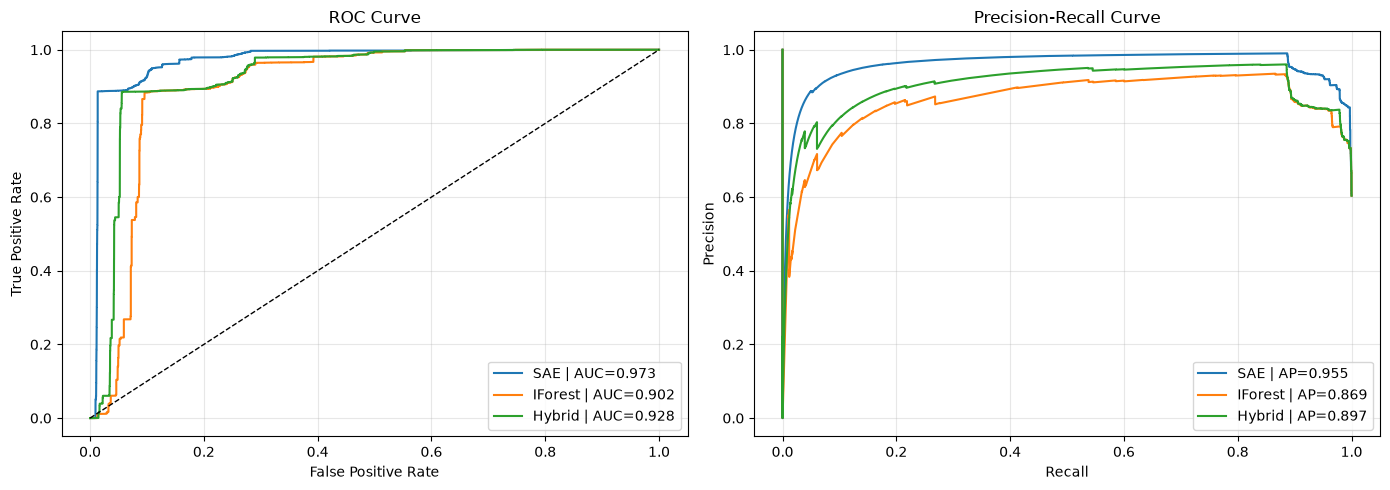

Kurva disimpan ke: results\roc_pr_curves.png


In [82]:
if len(np.unique(y_test)) > 1:

    scores_dict = {
        "SAE": sae_test_norm,
        "IForest": if_test_norm,
        "Hybrid": hybrid_test,
    }

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # --------------------------------------------------------
    # ROC Curve
    # --------------------------------------------------------
    for name, scores in scores_dict.items():
        fpr, tpr, _ = roc_curve(y_test, scores)
        roc_auc_value = auc(fpr, tpr)

        axes[0].plot(
            fpr,
            tpr,
            label=f"{name} | AUC={roc_auc_value:.3f}"
        )

    axes[0].plot([0, 1], [0, 1], "k--", linewidth=1)
    axes[0].set_xlabel("False Positive Rate")
    axes[0].set_ylabel("True Positive Rate")
    axes[0].set_title("ROC Curve")
    axes[0].grid(alpha=0.3)
    axes[0].legend()

    # --------------------------------------------------------
    # Precision-Recall Curve
    # --------------------------------------------------------
    for name, scores in scores_dict.items():
        precision_values, recall_values, _ = precision_recall_curve(y_test, scores)
        pr_auc_value = average_precision_score(y_test, scores)

        axes[1].plot(
            recall_values,
            precision_values,
            label=f"{name} | AP={pr_auc_value:.3f}"
        )

    axes[1].set_xlabel("Recall")
    axes[1].set_ylabel("Precision")
    axes[1].set_title("Precision-Recall Curve")
    axes[1].grid(alpha=0.3)
    axes[1].legend()

    plt.tight_layout()

    plot_path = RESULTS_DIR / "roc_pr_curves.png"
    plt.savefig(plot_path, dpi=200, bbox_inches="tight")
    plt.show()

    print("Kurva disimpan ke:", plot_path)

else:
    print("ROC/PR curve tidak dapat dibuat karena y_test hanya memiliki satu kelas.")